In [2]:
pip install shap

   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   - -------------------------------------- 1.8/43.0 MB 9.4 MB/s eta 0:00:05
   --- ------------------------------------ 3.9/43.0 MB 9.5 MB/s eta 0:00:05
   ----- ---------------------------------- 6.0/43.0 MB 9.8 MB/s eta 0:00:04
   ------- -------------------------------- 8.1/43.0 MB 9.9 MB/s eta 0:00:04
   --------- ------------------------------ 10.0/43.0 MB 9.9 MB/s eta 0:00:04
   ----------- ---------------------------- 12.1/43.0 MB 9.9 MB/s eta 0:00:04
   ------------- -------------------------- 14.2/43.0 MB 9.9 MB/s eta 0:00:03
   -------------- ------------------------- 16.0/43.0 MB 9.9 MB/s eta 0:00:03
   ---------------- ----------------------- 18.1/43.0 MB 9.9 MB/s eta 0:00:03
   ------------------ --------------------- 20.2/43.0 MB 9.9 MB/s eta 0:00:03
   -------------------- ------------------- 22.3/43.0 MB 9.9 MB/s eta 0:00:03
   ---------------------- ----------------- 24.1/43.0 MB 9.9 MB/s eta 0:00:0


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [5]:
price_model = joblib.load("../models/catboost_price_model.pkl")

production_model = joblib.load("../models/catboost_production.pkl")

In [7]:
price = pd.read_csv("../datasets/modeling/price_features.csv")

production = pd.read_csv("../datasets/processed/production_features.csv")

In [8]:
price_test = price[
    price["Year"] >= 2014
].copy()

In [9]:
production_test = production[
    production["Year"] >= 2014
].copy()

In [10]:
target = "Log_Price"

drop_cols = [
    "Avg_Modal_Price",
    "Log_Price"
]

X_price = price_test.drop(columns=drop_cols)

y_price = price_test[target]

In [11]:
target = "Log_Production"

drop_cols = [
    "Production",
    "Log_Production"
]

X_production = production_test.drop(columns=drop_cols)

y_production = production_test[target]

In [12]:
price_pred_log = price_model.predict(X_price)

price_pred = np.expm1(price_pred_log)

price_actual = np.expm1(y_price)

In [13]:
production_pred_log = production_model.predict(X_production)

production_pred = np.expm1(production_pred_log)

production_actual = np.expm1(y_production)

In [14]:
print("===== PRICE MODEL =====")

print("Log MAE:",
      mean_absolute_error(y_price,
                          price_pred_log))

print("Log RMSE:",
      np.sqrt(mean_squared_error(
          y_price,
          price_pred_log)))

print("Log R2:",
      r2_score(
          y_price,
          price_pred_log))

print()

print("Original MAE:",
      mean_absolute_error(
          price_actual,
          price_pred))

print("Original RMSE:",
      np.sqrt(mean_squared_error(
          price_actual,
          price_pred)))

print("Original R2:",
      r2_score(
          price_actual,
          price_pred))

===== PRICE MODEL =====
Log MAE: 0.15572125053484265
Log RMSE: 0.3003798629957794
Log R2: 0.8772831008749513

Original MAE: 1045.5081473183106
Original RMSE: 20386.743828970848
Original R2: 0.05374585300153478


In [15]:
print("===== PRODUCTION MODEL =====")

print("Log MAE:",
      mean_absolute_error(
          y_production,
          production_pred_log))

print("Log RMSE:",
      np.sqrt(mean_squared_error(
          y_production,
          production_pred_log)))

print("Log R2:",
      r2_score(
          y_production,
          production_pred_log))

print()

print("Original MAE:",
      mean_absolute_error(
          production_actual,
          production_pred))

print("Original RMSE:",
      np.sqrt(mean_squared_error(
          production_actual,
          production_pred)))

print("Original R2:",
      r2_score(
          production_actual,
          production_pred))

===== PRODUCTION MODEL =====
Log MAE: 0.3293632818439627
Log RMSE: 0.46549054164713966
Log R2: 0.9781748964455959

Original MAE: 223024.00502916958
Original RMSE: 6033059.681879228
Original R2: 0.918558056776429


In [17]:
print("Columns:", len(X_price.columns))
print("Importance:", len(price_model.get_feature_importance()))

Columns: 30
Importance: 26


In [18]:
print(X_price.columns.tolist())

['State', 'Year', 'Month', 'Standard_Crop', 'Median_Modal_Price', 'Price_STD', 'Min_Modal_Price', 'Max_Modal_Price', 'Market_Records', 'Unique_Markets', 'Avg_Temperature_C', 'Avg_DewPoint_C', 'Avg_Rainfall_mm', 'Avg_Wind_Speed', 'Avg_Surface_Pressure_hPa', 'Grid_Points', 'Price_Lag_1', 'Price_Lag_2', 'Price_Lag_3', 'Rolling_Mean_3', 'Rolling_Mean_6', 'Rolling_STD_3', 'Quarter', 'Month_Sin', 'Month_Cos', 'Previous_Change', 'Previous_Growth', 'Temp_Rainfall', 'Temp_DewPoint', 'Rainfall_Wind']


In [19]:
print(price_model.get_feature_importance())

[ 2.25321641  2.72558192  0.70786128  7.54766075  4.1491313   0.60803444
  0.94482795  1.55131571  0.41351975  0.85544451  1.06562218  0.88299921
 40.97309505  3.33191063  3.14231828  8.34664758  7.96609664  2.51934792
  0.29198315  1.04764141  0.95166979  2.67477404  3.18759818  0.61569672
  0.64617717  0.59982801]


In [20]:
print(type(price_model))

<class 'catboost.core.CatBoostRegressor'>


In [21]:
print(price_model.feature_names_)

['State', 'Year', 'Month', 'Standard_Crop', 'Market_Records', 'Unique_Markets', 'Avg_Temperature_C', 'Avg_DewPoint_C', 'Avg_Rainfall_mm', 'Avg_Wind_Speed', 'Avg_Surface_Pressure_hPa', 'Grid_Points', 'Price_Lag_1', 'Price_Lag_2', 'Price_Lag_3', 'Rolling_Mean_3', 'Rolling_Mean_6', 'Rolling_STD_3', 'Quarter', 'Month_Sin', 'Month_Cos', 'Previous_Change', 'Previous_Growth', 'Temp_Rainfall', 'Temp_DewPoint', 'Rainfall_Wind']


In [22]:
feature_names = price_model.feature_names_

X_price = price_test[feature_names].copy()

In [23]:
print(len(X_price.columns))
print(len(price_model.get_feature_importance()))

26
26


In [24]:
price_importance = pd.DataFrame({

    "Feature": X_price.columns,

    "Importance": price_model.get_feature_importance()

})

price_importance = price_importance.sort_values(

    "Importance",

    ascending=False

)

price_importance.head(20)

,Feature,Importance
12,Price_Lag_1,40.973095
15,Rolling_Mean_3,8.346648
16,Rolling_Mean_6,7.966097
3,Standard_Crop,7.547661
4,Market_Records,4.149131
13,Price_Lag_2,3.331911
22,Previous_Growth,3.187598
14,Price_Lag_3,3.142318
1,Year,2.725582
21,Previous_Change,2.674774


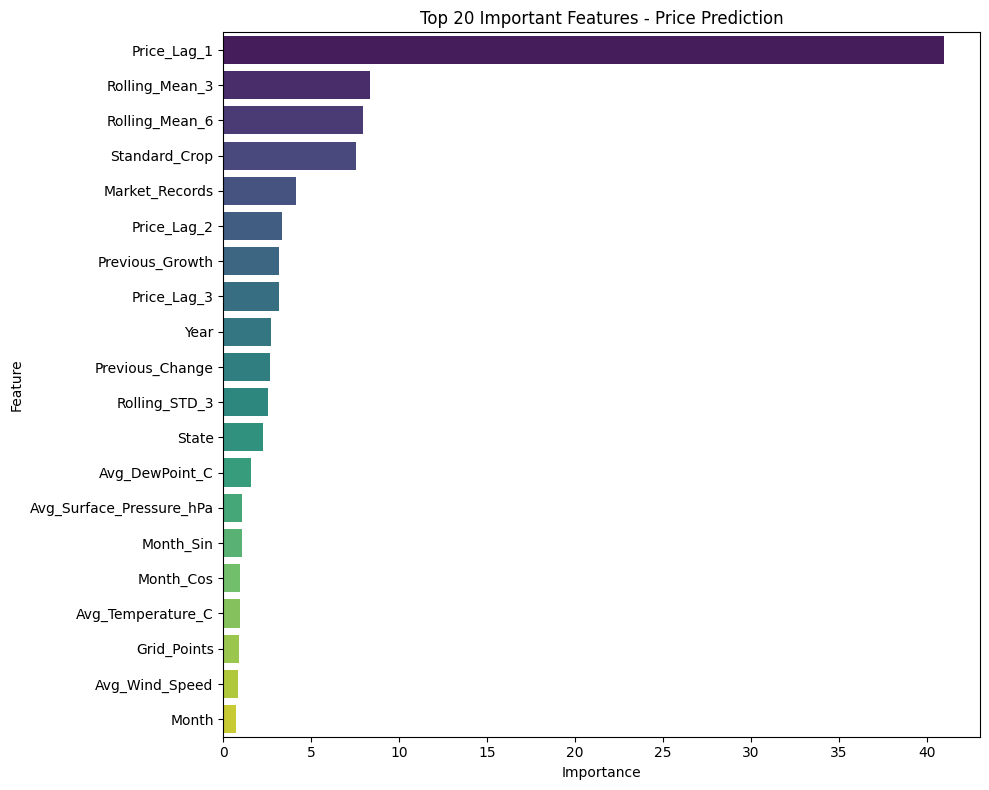

In [25]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=price_importance.head(20),
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Top 20 Important Features - Price Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [26]:
production_importance = pd.DataFrame({

    "Feature": production_model.feature_names_,

    "Importance": production_model.get_feature_importance()

})

production_importance = production_importance.sort_values(

    "Importance",

    ascending=False

)

production_importance.head(20)

,Feature,Importance
12,Log_Area,29.983670
5,Area,20.234961
4,Crop,19.455355
17,Rolling_Mean_5,7.707991
3,Season,4.746136
16,Rolling_Mean_3,4.017524
27,Area_Temperature,3.607082
0,State,1.786115
10,Avg_Annual_Surface_Pressure,1.246071
15,Production_Lag_3,1.216708


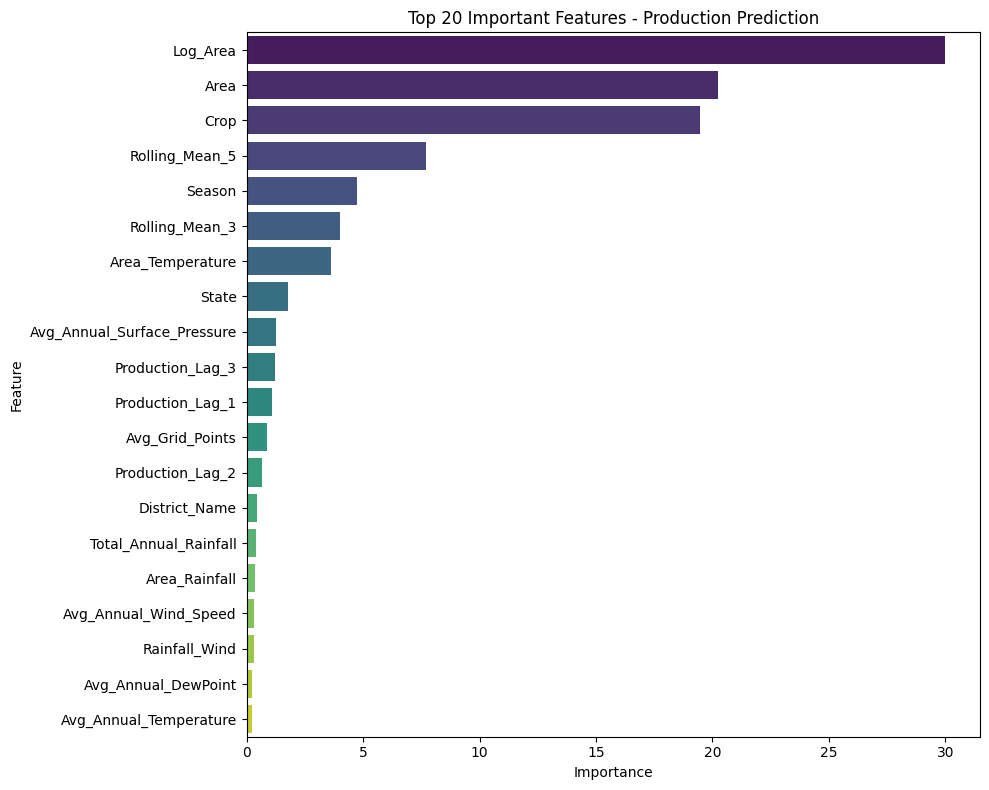

In [27]:
plt.figure(figsize=(10,8))

sns.barplot(

    data=production_importance.head(20),

    x="Importance",

    y="Feature",

    palette="viridis"

)

plt.title("Top 20 Important Features - Production Prediction")

plt.tight_layout()

plt.show()

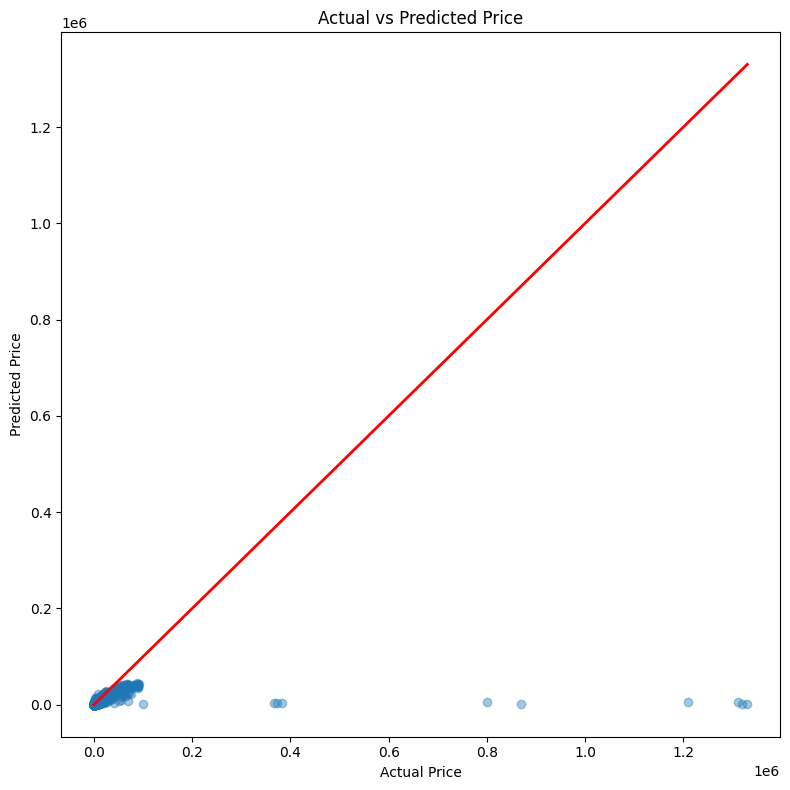

In [28]:
plt.figure(figsize=(8,8))

plt.scatter(
    price_actual,
    price_pred,
    alpha=0.4
)

plt.plot(
    [price_actual.min(), price_actual.max()],
    [price_actual.min(), price_actual.max()],
    color="red",
    linewidth=2
)

plt.xlabel("Actual Price")

plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted Price")

plt.tight_layout()

plt.show()

In [46]:
%whos

Variable                 Type                 Data/Info
-------------------------------------------------------
X_price                  DataFrame            Shape: (20722, 26)
X_production             DataFrame            Shape: (11332, 28)
crop_price_error         Series               Shape: (69,)
crop_production_error    Series               Shape: (73,)
drop_cols                list                 n=2
feature_names            list                 n=26
joblib                   module               <module 'joblib' from 'c:<...>es\\joblib\\__init__.py'>
mean_absolute_error      function             <function mean_absolute_e<...>or at 0x000001C5971507D0>
mean_squared_error       function             <function mean_squared_er<...>or at 0x000001C597150BF0>
np                       module               <module 'numpy' from 'c:\<...>ges\\numpy\\__init__.py'>
pd                       module               <module 'pandas' from 'c:<...>es\\pandas\\__init__.py'>
plt                      modu

In [47]:
list(globals().keys())

['__name__',
 '__doc__',
 '__package__',
 '__loader__',
 '__spec__',
 '__builtin__',
 '__builtins__',
 '_ih',
 '_oh',
 '_dh',
 'In',
 'Out',
 'get_ipython',
 'exit',
 'quit',
 'open',
 '_',
 '__',
 '___',
 '__vsc_ipynb_file__',
 '_i',
 '_ii',
 '_iii',
 '_i1',
 'joblib',
 'pd',
 'np',
 'plt',
 '_i2',
 '_exit_code',
 '_i3',
 'shap',
 '_i4',
 '_i5',
 'price_model',
 'production_model',
 '_i6',
 'warnings',
 'sns',
 'mean_absolute_error',
 'mean_squared_error',
 'r2_score',
 '_i7',
 'price',
 'production',
 '_i8',
 'price_test',
 '_i9',
 'production_test',
 '_i10',
 'target',
 'drop_cols',
 'X_price',
 'y_price',
 '_i11',
 'X_production',
 'y_production',
 '_i12',
 'price_pred_log',
 'price_pred',
 'price_actual',
 '_i13',
 'production_pred_log',
 'production_pred',
 'production_actual',
 '_i14',
 '_i15',
 '_i16',
 '_i17',
 '_i18',
 '_i19',
 '_i20',
 '_i21',
 '_i22',
 'feature_names',
 '_i23',
 '_i24',
 'price_importance',
 '_24',
 '_i25',
 '_i26',
 'production_importance',
 '_26',
 '_i27'

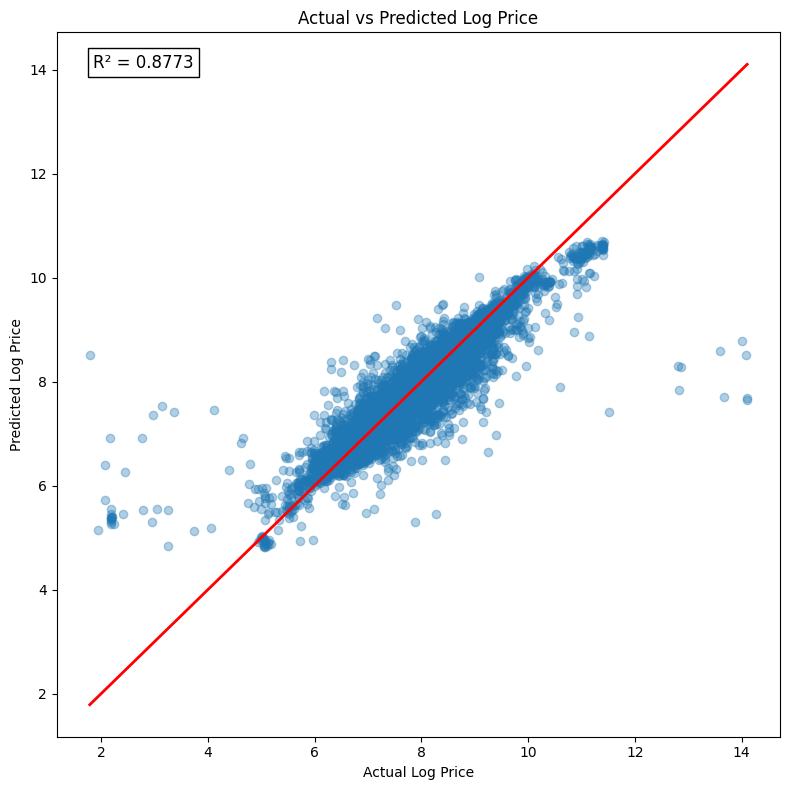

In [48]:
from sklearn.metrics import r2_score

plt.figure(figsize=(8,8))

plt.scatter(
    y_price,
    price_pred_log,
    alpha=0.35
)

plt.plot(
    [y_price.min(), y_price.max()],
    [y_price.min(), y_price.max()],
    color="red",
    linewidth=2
)

r2 = r2_score(y_price, price_pred_log)

plt.text(
    0.05,
    0.95,
    f"R² = {r2:.4f}",
    transform=plt.gca().transAxes,
    fontsize=12,
    bbox=dict(facecolor="white")
)

plt.xlabel("Actual Log Price")
plt.ylabel("Predicted Log Price")
plt.title("Actual vs Predicted Log Price")

plt.tight_layout()
plt.show()

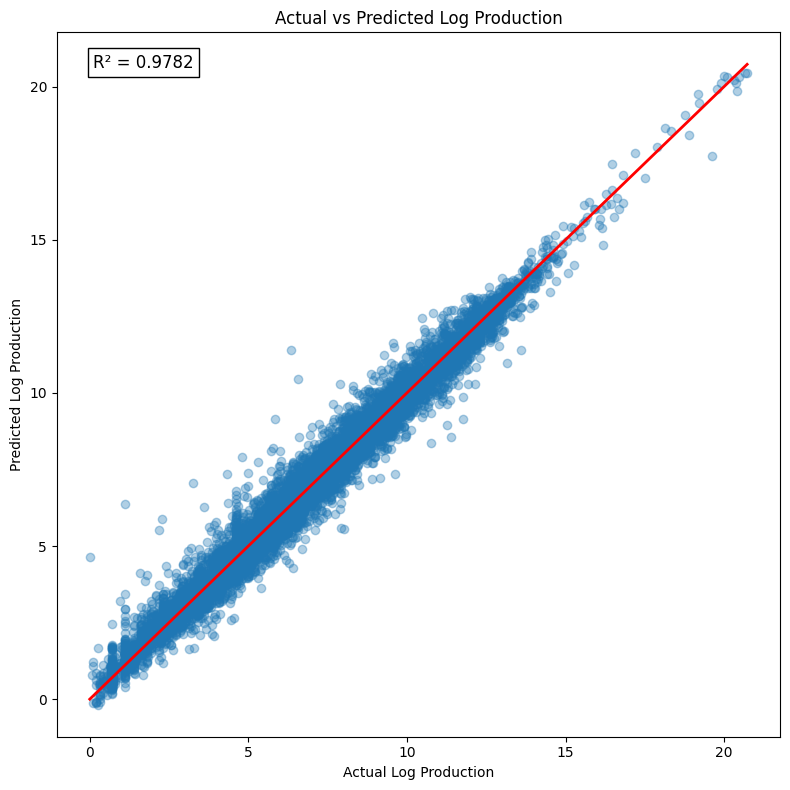

In [49]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_production,
    production_pred_log,
    alpha=0.35
)

plt.plot(
    [y_production.min(), y_production.max()],
    [y_production.min(), y_production.max()],
    color="red",
    linewidth=2
)

r2 = r2_score(y_production, production_pred_log)

plt.text(
    0.05,
    0.95,
    f"R² = {r2:.4f}",
    transform=plt.gca().transAxes,
    fontsize=12,
    bbox=dict(facecolor="white")
)

plt.xlabel("Actual Log Production")
plt.ylabel("Predicted Log Production")
plt.title("Actual vs Predicted Log Production")

plt.tight_layout()
plt.show()

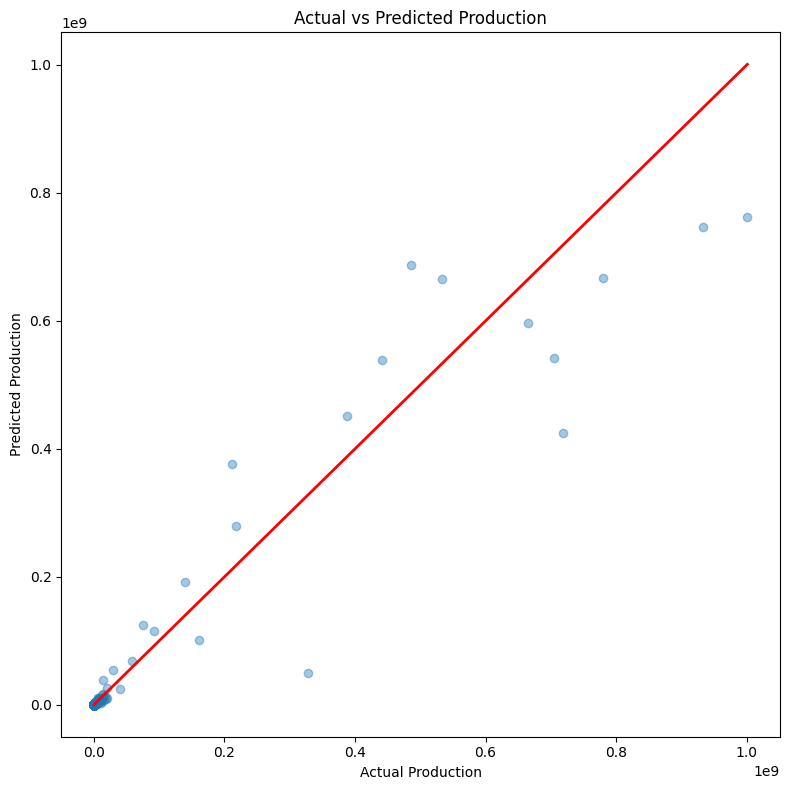

In [29]:
plt.figure(figsize=(8,8))

plt.scatter(
    production_actual,
    production_pred,
    alpha=0.4
)

plt.plot(
    [production_actual.min(), production_actual.max()],
    [production_actual.min(), production_actual.max()],
    color="red",
    linewidth=2
)

plt.xlabel("Actual Production")

plt.ylabel("Predicted Production")

plt.title("Actual vs Predicted Production")

plt.tight_layout()

plt.show()

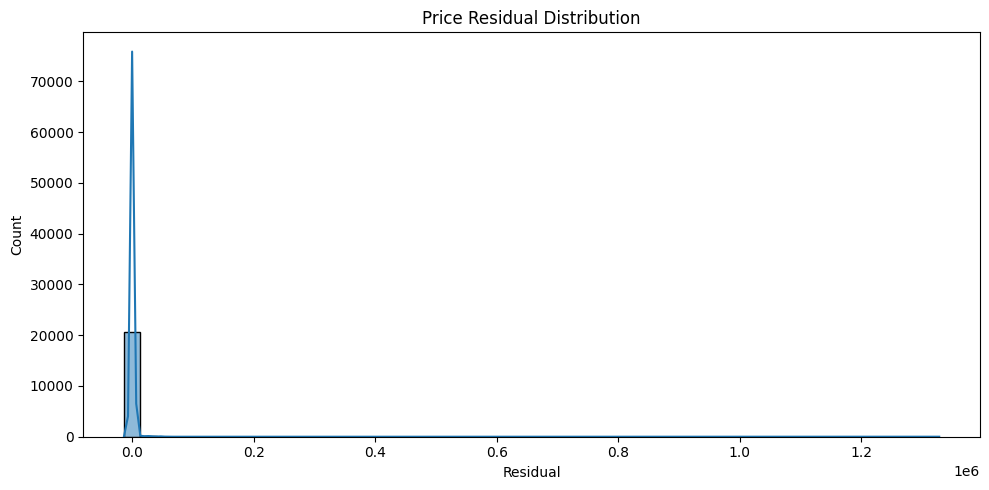

In [50]:
price_residual = price_actual - price_pred

plt.figure(figsize=(10,5))

sns.histplot(
    price_residual,
    bins=50,
    kde=True
)

plt.title("Price Residual Distribution")

plt.xlabel("Residual")

plt.tight_layout()

plt.show()

Text(0.5, 1.0, 'Log Residual Distribution')

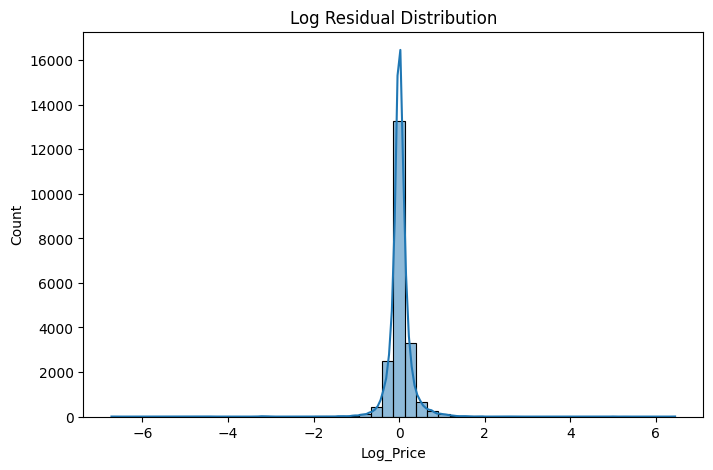

In [51]:
log_residual = y_price - price_pred_log

plt.figure(figsize=(8,5))
sns.histplot(log_residual, bins=50, kde=True)
plt.title("Log Residual Distribution")

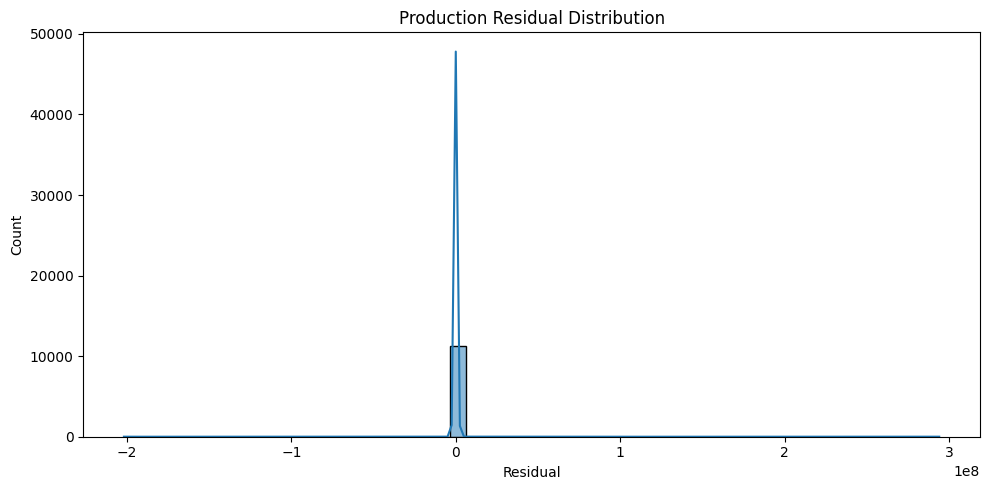

In [31]:
production_residual = production_actual - production_pred

plt.figure(figsize=(10,5))

sns.histplot(
    production_residual,
    bins=50,
    kde=True
)

plt.title("Production Residual Distribution")

plt.xlabel("Residual")

plt.tight_layout()

plt.show()

In [32]:
price_results = price_test.copy()

price_results["Actual"] = price_actual

price_results["Predicted"] = price_pred

price_results["Absolute_Error"] = (
    price_results["Actual"] -
    price_results["Predicted"]
).abs()

In [33]:
crop_price_error = (

    price_results

    .groupby("Standard_Crop")["Absolute_Error"]

    .mean()

    .sort_values()

)

crop_price_error.head(20)

Standard_Crop
Wheat            79.669538
Barley           83.604594
Maize            91.343204
Bajra            93.560334
Paddy           105.922148
Ragi            152.312561
Rice            155.965819
Potato          178.312171
Jowar           212.515871
Bottle Gourd    232.767431
Castor Seed     236.104007
Papaya          236.525255
Water Melon     238.092659
Sunflower       240.964060
Cabbage         240.979995
Banana          249.253078
Jute            249.604802
Soyabean        268.866945
Sweet Potato    269.789050
Groundnut       280.225089
Name: Absolute_Error, dtype: float64

In [34]:
production_results = production_test.copy()

production_results["Actual"] = production_actual

production_results["Predicted"] = production_pred

production_results["Absolute_Error"] = (
    production_results["Actual"] -
    production_results["Predicted"]
).abs()

In [35]:
crop_production_error = (

    production_results

    .groupby("Crop")["Absolute_Error"]

    .mean()

    .sort_values()

)

crop_production_error.head(20)

Crop
Moth                         2.039336
Blackgram                   12.708262
Sannhamp                    15.130963
Drum Stick                  24.029671
Other Cereals & Millets     25.261995
Coriander                   60.137425
Bean                        64.501095
Guar Seed                   68.939864
Linseed                     75.988168
Niger Seed                 126.492733
Horse-Gram                 128.373668
Castor Seed                179.826884
Cowpea(Lobia)              215.926855
Lentil                     230.397921
Sesamum                    230.711191
Other Kharif Pulses        258.018499
Small Millets              329.216074
Sunflower                  344.504654
Safflower                  390.662473
Moong(Green Gram)          431.159111
Name: Absolute_Error, dtype: float64

In [36]:
state_price_error = (

    price_results

    .groupby("State")["Absolute_Error"]

    .mean()

    .sort_values()

)

state_price_error

State
Uttar Pradesh                    233.928492
Andhra Pradesh                   269.229512
Telangana                        295.778349
Tamil Nadu                       298.666807
Rajasthan                        330.346786
Madhya Pradesh                   339.012506
Uttarakhand                      350.994485
Delhi                            378.195613
Puducherry                       410.268087
Haryana                          432.445274
Arunachal Pradesh                451.553140
Chhattisgarh                     465.873682
Punjab                           487.856157
West Bengal                      488.954748
Chandigarh                       489.653736
Jammu And Kashmir                522.271925
Maharashtra                      542.174638
Assam                            560.467046
Odisha                           565.249051
Himachal Pradesh                 572.904122
Manipur                          603.284145
Bihar                            827.506532
Karnataka                 

In [37]:
state_production_error = (

    production_results

    .groupby("State")["Absolute_Error"]

    .mean()

    .sort_values()

)

state_production_error

State
Sikkim                    4.071185e+02
Dadra And Nagar Haveli    5.245827e+02
Tripura                   5.717627e+02
Nagaland                  7.203449e+02
Arunachal Pradesh         8.574603e+02
Meghalaya                 1.129378e+03
Jammu And Kashmir         2.278611e+03
Chhattisgarh              2.434040e+03
Assam                     3.566843e+03
Odisha                    5.647534e+03
Goa                       9.133499e+03
Bihar                     1.211737e+04
Telangana                 1.572008e+04
Uttarakhand               1.612328e+04
Karnataka                 1.730482e+04
Uttar Pradesh             2.426132e+04
West Bengal               2.721098e+04
Punjab                    3.159680e+04
Maharashtra               7.558309e+04
Puducherry                1.824887e+05
Andhra Pradesh            1.204569e+06
Kerala                    7.362224e+06
Name: Absolute_Error, dtype: float64

In [56]:
print(production_results.columns.tolist())

['State', 'District_Name', 'Year', 'Season', 'Crop', 'Area', 'Production', 'Avg_Annual_Temperature', 'Avg_Annual_DewPoint', 'Total_Annual_Rainfall', 'Avg_Annual_Wind_Speed', 'Avg_Annual_Surface_Pressure', 'Avg_Grid_Points', 'Log_Production', 'Log_Area', 'Production_Lag_1', 'Production_Lag_2', 'Production_Lag_3', 'Rolling_Mean_3', 'Rolling_Mean_5', 'Rolling_STD_3', 'Previous_Change', 'Previous_Growth', 'Years_From_Start', 'Year_Squared', 'Temp_Rainfall', 'Temp_DewPoint', 'Rainfall_Wind', 'Area_Rainfall', 'Area_Temperature', 'Actual', 'Predicted', 'Absolute_Error', 'Percentage_Error']


In [72]:
print(price_results.columns.tolist())

['State', 'Year', 'Month', 'Standard_Crop', 'Avg_Modal_Price', 'Median_Modal_Price', 'Price_STD', 'Min_Modal_Price', 'Max_Modal_Price', 'Market_Records', 'Unique_Markets', 'Avg_Temperature_C', 'Avg_DewPoint_C', 'Avg_Rainfall_mm', 'Avg_Wind_Speed', 'Avg_Surface_Pressure_hPa', 'Grid_Points', 'Log_Price', 'Price_Lag_1', 'Price_Lag_2', 'Price_Lag_3', 'Rolling_Mean_3', 'Rolling_Mean_6', 'Rolling_STD_3', 'Quarter', 'Month_Sin', 'Month_Cos', 'Previous_Change', 'Previous_Growth', 'Temp_Rainfall', 'Temp_DewPoint', 'Rainfall_Wind', 'Actual', 'Predicted', 'Absolute_Error', 'Percentage_Error']


In [ ]:
print(production_results.columns.tolist())

In [54]:
production_results["Percentage_Error"] = (
    production_results["Absolute_Error"]
    /
    production_results["Actual"]
) * 100

In [57]:
price_results["Percentage_Error"] = (
    price_results["Absolute_Error"]
    /
    price_results["Actual"]
) * 100

In [60]:
production_results["Percentage_Error"] = np.where(
    production_actual.values == 0,
    np.nan,
    (production_results["Absolute_Error"] / production_actual.values) * 100
)

In [62]:
price_results["Percentage_Error"] = np.where(
    price_actual.values == 0,
    np.nan,
    (price_results["Absolute_Error"] / price_actual.values) * 100
)

In [63]:
state_production_percentage_error = (
    production_results
    .groupby("State")["Percentage_Error"]
    .mean()
    .sort_values()
)

print(state_production_percentage_error)

State
Sikkim                      10.403320
Tripura                     17.005645
Punjab                      22.679547
Nagaland                    25.034923
Assam                       25.280128
Dadra And Nagar Haveli      26.077540
Arunachal Pradesh           29.849216
West Bengal                 30.258947
Bihar                       30.698632
Puducherry                  31.249497
Karnataka                   35.132387
Meghalaya                   37.005477
Uttar Pradesh               40.886224
Odisha                      42.316749
Uttarakhand                 48.000243
Telangana                   48.932259
Andhra Pradesh              59.808859
Chhattisgarh                68.681762
Kerala                      68.736322
Maharashtra                 89.560777
Jammu And Kashmir          154.786787
Goa                       1116.747466
Name: Percentage_Error, dtype: float64


In [64]:
state_price_percentage_error = (
    price_results
    .groupby("State")["Percentage_Error"]
    .mean()
    .sort_values()
)

print(state_price_percentage_error)

State
Kerala                           9.492338
Uttar Pradesh                   10.465912
Rajasthan                       11.526363
Puducherry                      11.548771
Karnataka                       11.574408
Manipur                         12.039766
Uttarakhand                     14.041153
Gujarat                         14.168059
Jharkhand                       14.618203
Odisha                          14.942050
Delhi                           15.072955
Chhattisgarh                    15.141023
Haryana                         15.399554
Himachal Pradesh                16.238358
West Bengal                     16.473761
Jammu And Kashmir               16.782714
Arunachal Pradesh               17.209909
Punjab                          17.551040
Bihar                           17.831754
Maharashtra                     19.011051
Andhra Pradesh                  19.193607
Assam                           19.786951
Madhya Pradesh                  21.125589
Tamil Nadu                  

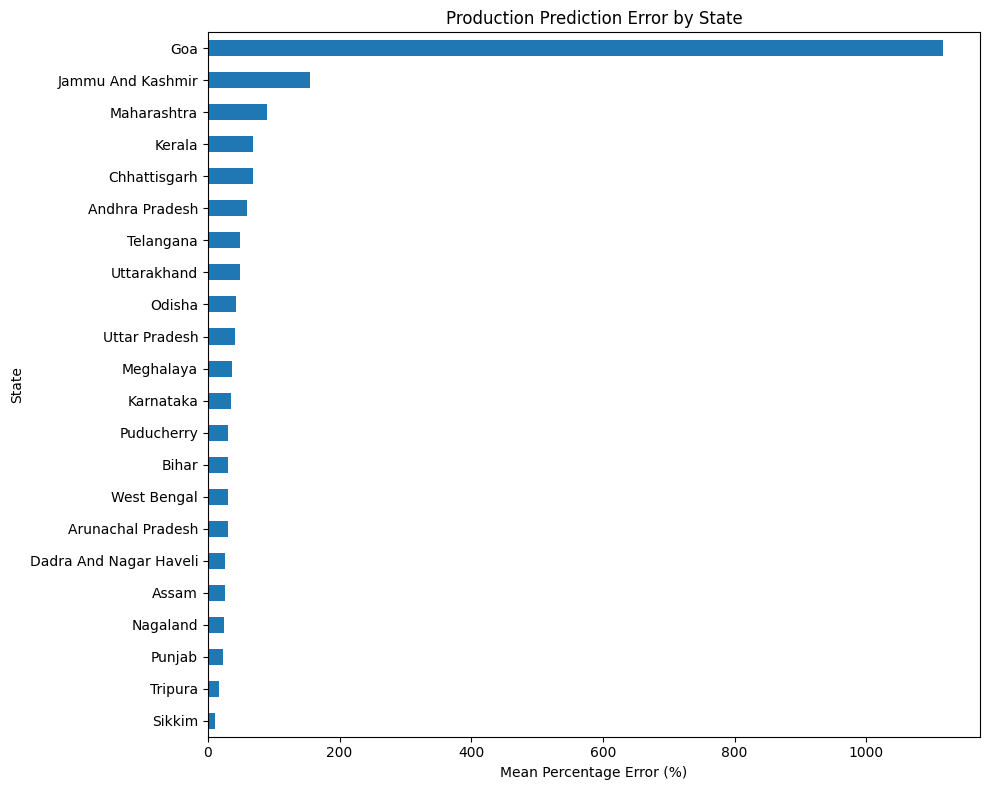

In [65]:
plt.figure(figsize=(10, 8))

state_production_percentage_error.plot.barh()

plt.xlabel("Mean Percentage Error (%)")
plt.title("Production Prediction Error by State")
plt.tight_layout()
plt.show()

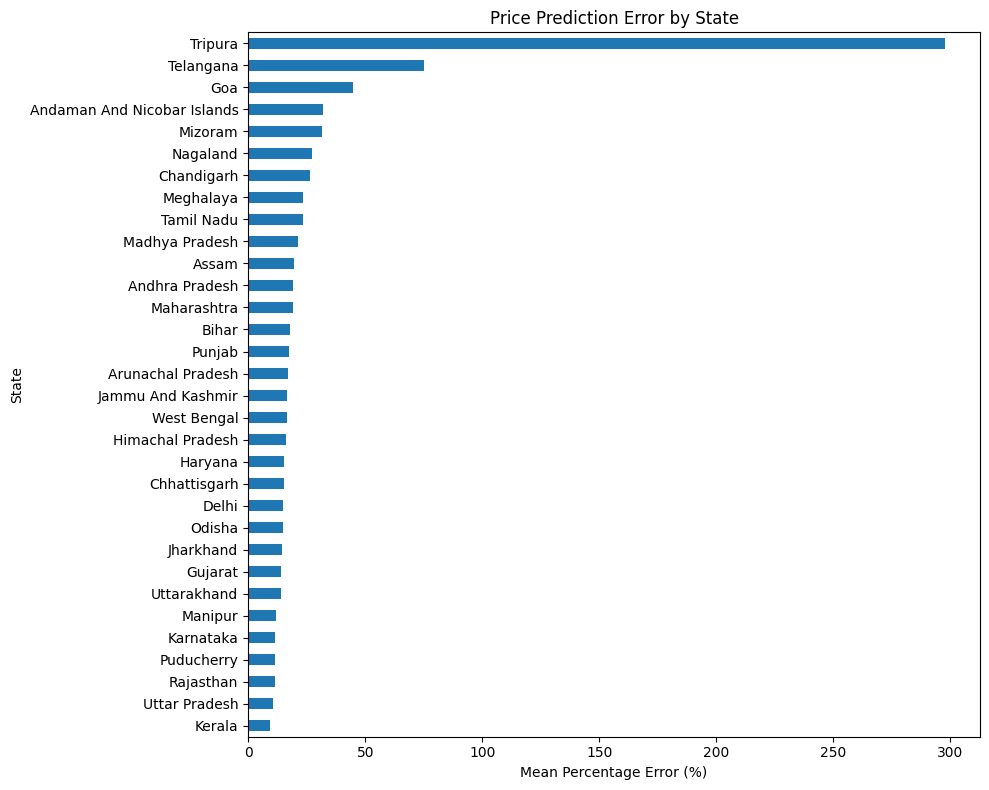

In [66]:
plt.figure(figsize=(10, 8))

state_price_percentage_error.plot.barh()

plt.xlabel("Mean Percentage Error (%)")
plt.title("Price Prediction Error by State")
plt.tight_layout()
plt.show()

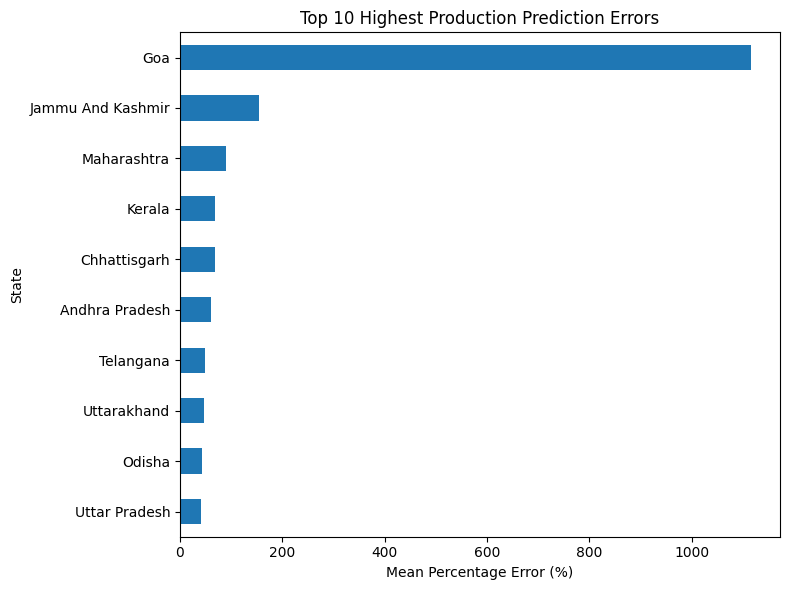

In [67]:
plt.figure(figsize=(8,6))

state_production_percentage_error.tail(10).plot.barh()

plt.title("Top 10 Highest Production Prediction Errors")
plt.xlabel("Mean Percentage Error (%)")

plt.tight_layout()
plt.show()

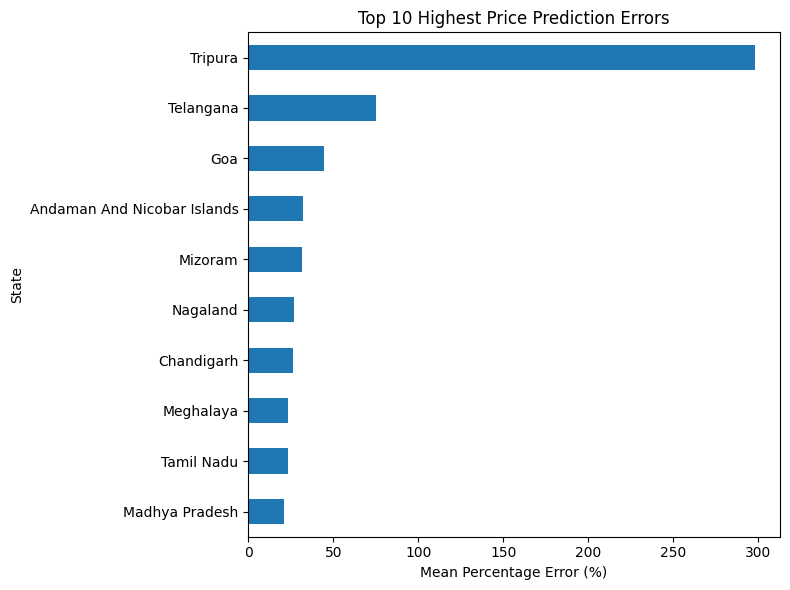

In [68]:
plt.figure(figsize=(8,6))

state_price_percentage_error.tail(10).plot.barh()

plt.title("Top 10 Highest Price Prediction Errors")
plt.xlabel("Mean Percentage Error (%)")

plt.tight_layout()
plt.show()

In [69]:
production_results.groupby("State").size().sort_values()

State
Dadra And Nagar Haveli       8
Goa                         20
Puducherry                  56
Sikkim                      70
Jammu And Kashmir          125
Arunachal Pradesh          144
Tripura                    160
Punjab                     174
Kerala                     205
Meghalaya                  269
Telangana                  335
Nagaland                   340
Uttarakhand                426
West Bengal                502
Maharashtra                551
Andhra Pradesh             695
Bihar                      879
Chhattisgarh               911
Assam                      968
Odisha                    1064
Karnataka                 1307
Uttar Pradesh             2123
dtype: int64

In [70]:
price_results.groupby("State").size().sort_values()

State
Arunachal Pradesh                42
Andaman And Nicobar Islands      82
Chandigarh                       93
Goa                             165
Puducherry                      180
Bihar                           209
Nagaland                        265
Mizoram                         354
Manipur                         395
Tripura                         403
Meghalaya                       500
Jammu And Kashmir               525
Chhattisgarh                    583
Tamil Nadu                      587
Himachal Pradesh                587
Jharkhand                       626
Assam                           684
West Bengal                     710
Delhi                           797
Punjab                          821
Uttar Pradesh                   885
Uttarakhand                     887
Andhra Pradesh                  895
Haryana                         944
Telangana                       950
Odisha                          968
Kerala                         1047
Maharashtra           

In [73]:
price_results.loc[
    price_results["State"] == "Tripura",
    ["Standard_Crop", "Actual", "Predicted", "Absolute_Error", "Percentage_Error"]
].sort_values("Percentage_Error", ascending=False).head(20)

,Standard_Crop,Actual,Predicted,Absolute_Error,Percentage_Error
104370,Bhindi,5.000000,4975.661045,4970.661045,99413.220907
104371,Bhindi,7.750000,1007.065811,999.315811,12894.397565
104101,Apple,1500.000000,8381.538541,6881.538541,458.769236
104099,Apple,2000.000000,8091.893291,6091.893291,304.594665
106113,Sesamum,870000.000000,2242.609243,867757.390757,99.742229
104912,Cowpea(Lobia),2059.090909,4063.773387,2004.682478,97.357648
104454,Bitter Gourd,1848.979592,3595.675626,1746.696034,94.468108
104372,Bhindi,4653.604167,662.176767,3991.427400,85.770668
104872,Cauliflower,10100.000000,1655.340138,8444.659862,83.610494
104800,Carrot,9500.000000,2132.408840,7367.591160,77.553591


In [75]:
price_results.loc[
    price_results["State"] == "Tripura",
    "Actual"
].describe()

count       403.000000
mean       5757.390341
std       43297.376291
min           5.000000
25%        1374.681402
50%        2409.466019
75%        4303.787879
max      870000.000000
Name: Actual, dtype: float64

In [76]:
price_results.loc[
    price_results["Actual"] == 870000
]

,State,Year,Month,Standard_Crop,Avg_Modal_Price,Median_Modal_Price,Price_STD,Min_Modal_Price,Max_Modal_Price,Market_Records,...,Month_Cos,Previous_Change,Previous_Growth,Temp_Rainfall,Temp_DewPoint,Rainfall_Wind,Actual,Predicted,Absolute_Error,Percentage_Error


In [77]:
price[
    (price["State"] == "Tripura") &
    (price["Standard_Crop"] == "Sesamum")
].sort_values("Median_Modal_Price", ascending=False).head()

,State,Year,Month,Standard_Crop,Avg_Modal_Price,Median_Modal_Price,Price_STD,Min_Modal_Price,Max_Modal_Price,Market_Records,...,Rolling_Mean_6,Rolling_STD_3,Quarter,Month_Sin,Month_Cos,Previous_Change,Previous_Growth,Temp_Rainfall,Temp_DewPoint,Rainfall_Wind
106113,Tripura,2014,8,Sesamum,870000.000000,870000.0,0.000000,870000.0,870000.0,1,...,7.573616,0.226179,3,-8.660254e-01,-0.500000,0.450328,0.062107,227.315860,2.356934,22.185272
106112,Tripura,2006,11,Sesamum,2210.000000,2210.0,0.000000,2210.0,2210.0,1,...,7.570259,0.199760,4,-5.000000e-01,0.866025,-0.188100,-0.025286,13.297822,3.656158,0.271162
106109,Tripura,2004,1,Sesamum,2100.000000,2100.0,0.000000,2100.0,2100.0,1,...,7.688649,0.011638,1,5.000000e-01,0.866025,-0.007148,-0.000928,2.195163,4.252624,0.097655
106110,Tripura,2004,6,Sesamum,1700.000000,1700.0,40.824829,1650.0,1750.0,4,...,7.684536,0.029129,2,1.224647e-16,-1.000000,-0.046498,-0.006041,376.912540,2.531250,30.980087
106111,Tripura,2004,7,Sesamum,1408.333333,1400.0,100.366974,1300.0,1550.0,18,...,7.644558,0.137340,3,-5.000000e-01,-0.866025,-0.211197,-0.027607,370.383450,2.020996,34.923843


A small number of extreme commodity price outliers were identified (e.g., Sesamum in Tripura, August 2014 with a single market record). These observations likely originate from data-entry or source inconsistencies and disproportionately affect percentage-based error metrics. Future work may include robust outlier filtering or validation against original AGMARKNET records.

In [79]:
plt.savefig("../reports/price_feature_importance.png", dpi=300)

<Figure size 640x480 with 0 Axes>

In [80]:
price["Avg_Modal_Price"].describe(percentiles=[0.90, 0.95, 0.99, 0.995, 0.999])

count    1.202980e+05
mean     2.474805e+03
std      9.459801e+03
min      3.500000e-01
90%      4.789002e+03
95%      6.689344e+03
99%      1.300000e+04
99.5%    1.784442e+04
99.9%    5.153657e+04
max      1.330147e+06
Name: Avg_Modal_Price, dtype: float64

In [81]:
price[price["Avg_Modal_Price"] > 100000].shape

(14, 32)

In [82]:
price[price["Avg_Modal_Price"] > 100000][
    ["State", "Standard_Crop", "Year", "Month", "Avg_Modal_Price", "Market_Records"]
].sort_values("Avg_Modal_Price", ascending=False)

,State,Standard_Crop,Year,Month,Avg_Modal_Price,Market_Records
18706,Goa,Coconut,2014,10,1.330147e+06,17
18704,Goa,Coconut,2014,8,1.320000e+06,10
18707,Goa,Coconut,2014,11,1.311000e+06,25
18708,Goa,Coconut,2014,12,1.209375e+06,16
106113,Tripura,Sesamum,2014,8,8.700000e+05,1
18664,Goa,Coconut,2010,2,8.510694e+05,18
18709,Goa,Coconut,2015,1,8.004500e+05,3
52728,Kerala,Coconut,2004,11,4.168288e+05,13
18717,Goa,Coconut,2015,10,3.836739e+05,23
18718,Goa,Coconut,2015,11,3.729159e+05,49


Outlier Analysis: The aggregated price dataset contains 14 observations (0.012% of all records) with average prices exceeding ₹100,000. Most of these correspond to Coconut prices in Goa across multiple consecutive months and years with several market observations, suggesting legitimate market-specific pricing units. Two isolated observations (Tripura–Sesamum and Odisha–Turmeric), each based on a single market record, appear anomalous and are likely due to data inconsistencies. Given their negligible proportion in the dataset, these observations were retained, although they contribute to unusually high percentage errors for a few states.